In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [ ]:
import os

os.makedirs("/root/.kaggle", exist_ok=True)

!cp kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
!mkdir -p /content/dataset

!kaggle datasets download \
    -d yash9439/eng-hinglish-machine-translation \
    -p /content/dataset \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/yash9439/eng-hinglish-machine-translation
License(s): apache-2.0
100% 476k/476k [00:00<00:00, 551kB/s]



In [ ]:
import os

for root, dirs, filenames in os.walk("/content/dataset"):
    for filename in filenames:
        print(os.path.join(root, filename))

/content/dataset/Eng - Hinglish/test.txt
/content/dataset/Eng - Hinglish/train.txt
/content/dataset/Eng - Hinglish/dev.txt


In [ ]:
import pandas as pd
import glob
import os

paths = []
# Added **/*.txt to find the text-based datasets
for pattern in ["**/*.csv", "**/*.tsv", "**/*.json", "**/*.jsonl", "**/*.txt"]:
    paths.extend(
        glob.glob("/content/dataset/" + pattern, recursive=True)
    )

def load_file(path):
    if path.endswith((".tsv", ".txt")):
        # Try tab-separated first since parallel text files are often tab-separated
        return pd.read_csv(path, sep="\t", names=["English", "Hinglish"], header=None, on_bad_lines='skip')
    if path.endswith((".json", ".jsonl")):
        try:
            return pd.read_json(path, lines=True)
        except ValueError:
            return pd.read_json(path)
    try:
        return pd.read_csv(path)
    except Exception:
        return pd.read_csv(path, sep=None, engine="python")

tables = []
for path in paths:
    try:
        table = load_file(path)
        if len(table) > 0:
            tables.append((path, table))
    except Exception as e:
        print("Could not load:", path, e)

if not tables:
    raise ValueError("No readable data table found. Check the file list.")

data_path, df = max(tables, key=lambda item: len(item[1]))

print("Loaded file:", data_path)
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())

Loaded file: /content/dataset/Eng - Hinglish/train.txt
Dataset shape: (7040, 2)
Column names: ['English', 'Hinglish']


,English,Hinglish
0,Batman vs Superman,batman vs superman
1,"The director is Zack Snyder , 27 % Rotten Toma...","Zack Snyder director हैं , 27 % Rotten Tomatoe..."
2,Not very popular it seems,लगता है बहुत popular नहीं है
3,But the audiences liked it . It has a B cinema...,"but audience ने like किया , इसका cinema score ..."
4,Yes,yes


In [ ]:
print(df.columns.tolist())

['English', 'Hinglish']


In [ ]:
english_col = "English"       # Capitalized 'E' to match the actual column name
hinglish_col = "Hinglish"     # Capitalized 'H' to match the actual column name

print(df[[english_col, hinglish_col]].head())

                                             English  \
0                                 Batman vs Superman   
1  The director is Zack Snyder , 27 % Rotten Toma...   
2                          Not very popular it seems   
3  But the audiences liked it . It has a B cinema...   
4                                                Yes   

                                            Hinglish  
0                                batman vs superman   
1  Zack Snyder director हैं , 27 % Rotten Tomatoe...  
2                      लगता है बहुत popular नहीं है   
3  but audience ने like किया , इसका cinema score ...  
4                                               yes   


In [ ]:
import re

data = df[[english_col, hinglish_col]].dropna().copy()

def clean_text(text):
    text = str(text).lower().strip()
    text = re.sub(r"\s+", " ", text)
    return text

data[english_col] = data[english_col].apply(clean_text)
data[hinglish_col] = data[hinglish_col].apply(clean_text)

data = data[
    (data[english_col] != "") &
    (data[hinglish_col] != "")
]

data = data.drop_duplicates().reset_index(drop=True)

print("Total cleaned sentence pairs:", len(data))
display(data.head())

Total cleaned sentence pairs: 6538


,English,Hinglish
0,batman vs superman,batman vs superman
1,"the director is zack snyder , 27 % rotten toma...","zack snyder director हैं , 27 % rotten tomatoe..."
2,not very popular it seems,लगता है बहुत popular नहीं है
3,but the audiences liked it . it has a b cinema...,"but audience ने like किया , इसका cinema score ..."
4,yes,yes


In [ ]:
from sklearn.model_selection import train_test_split

english_sentences = data[english_col].tolist()

hinglish_sentences = [
    "startseq " + sentence + " endseq"
    for sentence in data[hinglish_col].tolist()
]

en_train, en_test, hi_train, hi_test = train_test_split(
    english_sentences,
    hinglish_sentences,
    test_size=0.15,
    random_state=42
)

print("Training pairs:", len(en_train))
print("Testing pairs:", len(en_test))

Training pairs: 5557
Testing pairs: 981


In [ ]:
!pip install -q tensorflow

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer

en_tokenizer = Tokenizer(oov_token="<OOV>")
hi_tokenizer = Tokenizer(oov_token="<OOV>")

en_tokenizer.fit_on_texts(en_train)
hi_tokenizer.fit_on_texts(hi_train)

en_train_seq = en_tokenizer.texts_to_sequences(en_train)
en_test_seq = en_tokenizer.texts_to_sequences(en_test)

hi_train_seq = hi_tokenizer.texts_to_sequences(hi_train)
hi_test_seq = hi_tokenizer.texts_to_sequences(hi_test)

EN_VOCAB_SIZE = len(en_tokenizer.word_index) + 1
HI_VOCAB_SIZE = len(hi_tokenizer.word_index) + 1

print("English vocabulary size:", EN_VOCAB_SIZE)
print("Hinglish vocabulary size:", HI_VOCAB_SIZE)

print("English example:", en_train[0])
print("English IDs:", en_train_seq[0])

print("Hinglish example:", hi_train[0])
print("Hinglish IDs:", hi_train_seq[0])

English vocabulary size: 5235
Hinglish vocabulary size: 7008
English example: haha yeah
English IDs: [172, 40]
Hinglish example: startseq haha हाँ यार endseq
Hinglish IDs: [2, 234, 40, 89, 3]


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_EN_LEN = max(
    len(s) for s in en_train_seq + en_test_seq
)
MAX_HI_LEN = max(
    len(s) for s in hi_train_seq + hi_test_seq
)

en_train_pad = pad_sequences(
    en_train_seq, maxlen=MAX_EN_LEN, padding="post"
)
en_test_pad = pad_sequences(
    en_test_seq, maxlen=MAX_EN_LEN, padding="post"
)

hi_train_pad = pad_sequences(
    hi_train_seq, maxlen=MAX_HI_LEN, padding="post"
)
hi_test_pad = pad_sequences(
    hi_test_seq, maxlen=MAX_HI_LEN, padding="post"
)

print("English padded shape:", en_train_pad.shape)
print("Hinglish padded shape:", hi_train_pad.shape)
print("Padded example:", en_train_pad[0])

English padded shape: (5557, 248)
Hinglish padded shape: (5557, 340)
Padded example: [172  40   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   

In [ ]:
import numpy as np

decoder_input_train = hi_train_pad[:, :-1]
decoder_target_train = hi_train_pad[:, 1:]

decoder_input_test = hi_test_pad[:, :-1]
decoder_target_test = hi_test_pad[:, 1:]

# Ignore padding zeros when calculating the loss.
train_weights = (decoder_target_train != 0).astype("float32")
test_weights = (decoder_target_test != 0).astype("float32")

print("Decoder input shape:", decoder_input_train.shape)
print("Decoder target shape:", decoder_target_train.shape)

Decoder input shape: (5557, 339)
Decoder target shape: (5557, 339)


In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.models import Model

EMBEDDING_DIM = 128
LATENT_DIM = 256

# Encoder
encoder_inputs = Input(shape=(None,), name="encoder_inputs")

encoder_embedding_layer = Embedding(
    EN_VOCAB_SIZE,
    EMBEDDING_DIM,
    mask_zero=True
)

encoder_embedded = encoder_embedding_layer(encoder_inputs)

encoder_lstm = LSTM(
    LATENT_DIM,
    return_state=True,
    name="encoder_lstm"
)

_, state_h, state_c = encoder_lstm(encoder_embedded)
encoder_states = [state_h, state_c]

# Decoder
decoder_inputs = Input(shape=(None,), name="decoder_inputs")

decoder_embedding_layer = Embedding(
    HI_VOCAB_SIZE,
    EMBEDDING_DIM,
    mask_zero=True
)

decoder_embedded = decoder_embedding_layer(decoder_inputs)

decoder_lstm = LSTM(
    LATENT_DIM,
    return_sequences=True,
    return_state=True,
    name="decoder_lstm"
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedded,
    initial_state=encoder_states
)

decoder_dense = Dense(
    HI_VOCAB_SIZE,
    activation="softmax"
)

decoder_outputs = decoder_dense(decoder_outputs)

model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy"
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 128) │    670,080 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, None, 128) │    897,024 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 256),     │    394,240 │ embedding[0][0],  │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │    394,240 │ embedding_1[0][0… │
│                     │ 256), (None,      │            │ encoder_lstm[0][… │
│                     │ 256), (None,      │            │ encoder_lstm[0][… │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, None,      │  1,801,056 │ decoder_lstm[0][… │
│                     │ 7008)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,156,640 (15.86 MB)

 Trainable params: 4,156,640 (15.86 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
en_train_small = en_train_pad[:5000]
decoder_input_small = decoder_input_train[:5000]
decoder_target_small = decoder_target_train[:5000]
train_weights_small = train_weights[:5000]

history = model.fit(
    [en_train_small, decoder_input_small],
    decoder_target_small[..., np.newaxis],
    sample_weight=train_weights_small,
    validation_split=0.1,
    epochs=5,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 863s 24s/step - loss: 5.8366 - val_loss: 5.7791
Epoch 2/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 840s 23s/step - loss: 5.6629 - val_loss: 5.7054
Epoch 3/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 866s 23s/step - loss: 5.5572 - val_loss: 5.6638
Epoch 4/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 839s 23s/step - loss: 5.4670 - val_loss: 5.6292
Epoch 5/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 853s 23s/step - loss: 5.3874 - val_loss: 5.5954


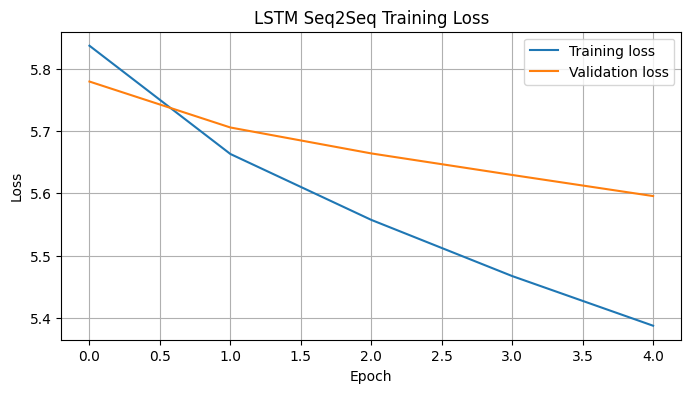

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Seq2Seq Training Loss")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
# Encoder inference model
encoder_model = Model(encoder_inputs, encoder_states)

# Decoder inference inputs
state_h_input = Input(shape=(LATENT_DIM,))
state_c_input = Input(shape=(LATENT_DIM,))
token_input = Input(shape=(1,))

decoder_one_embedding = decoder_embedding_layer(token_input)

decoder_one_output, new_h, new_c = decoder_lstm(
    decoder_one_embedding,
    initial_state=[state_h_input, state_c_input]
)

decoder_one_probs = decoder_dense(decoder_one_output)

decoder_model = Model(
    [token_input, state_h_input, state_c_input],
    [decoder_one_probs, new_h, new_c]
)

# Convert predicted IDs back to words
hi_index_word = {
    idx: word
    for word, idx in hi_tokenizer.word_index.items()
}

START_ID = hi_tokenizer.word_index["startseq"]
END_ID = hi_tokenizer.word_index["endseq"]

In [26]:
def translate(sentence):
    sentence = sentence.lower().strip()

    sequence = en_tokenizer.texts_to_sequences([sentence])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_EN_LEN,
        padding="post"
    )

    h, c = encoder_model.predict(padded, verbose=0)

    token = np.array([[START_ID]])
    result = []

    for _ in range(MAX_HI_LEN):
        probabilities, h, c = decoder_model.predict(
            [token, h, c],
            verbose=0
        )

        next_id = int(np.argmax(probabilities[0, -1, :]))

        if next_id == END_ID or next_id == 0:
            break

        word = hi_index_word.get(next_id, "")

        if word and word != "startseq":
            result.append(word)

        token = np.array([[next_id]])

    return " ".join(result)

In [27]:
from nltk.translate.bleu_score import (
    corpus_bleu,
    SmoothingFunction
)

references = []
predictions = []

limit = min(200, len(en_test))

for i in range(limit):
    predicted = translate(en_test[i])

    reference = (
        hi_test[i]
        .replace("startseq", "")
        .replace("endseq", "")
        .strip()
    )

    references.append([reference.split()])
    predictions.append(predicted.split())

bleu_score = corpus_bleu(
    references,
    predictions,
    smoothing_function=SmoothingFunction().method1
)

print("Number of test translations:", limit)
print("BLEU score:", round(bleu_score, 4))
print("BLEU × 100:", round(bleu_score * 100, 2))

Number of test translations: 200
BLEU score: 0.0023
BLEU × 100: 0.23


In [28]:
for i in range(min(10, limit)):
    print("English:", en_test[i])
    print("Actual Hinglish:", " ".join(references[i][0]))
    print("Predicted Hinglish:", " ".join(predictions[i]))
    print("-" * 50)

English: does emma stone sing as well ?
Actual Hinglish: क्या emma stone भी अच्छा सिंह कर सकती है ?
Predicted Hinglish: मुझे वह movie है
--------------------------------------------------
English: do you want to know something about plot ?
Actual Hinglish: क्या तुम plot के बारे में जानना चाहते हो ?
Predicted Hinglish: मुझे वह movie है कि है
--------------------------------------------------
English: did you know sean parker was the founder of napster ?
Actual Hinglish: क्या तुम जानते हो sean parker napster का founder था
Predicted Hinglish: मुझे वह movie है कि वह movie है
--------------------------------------------------
English: they all do an amazing job , and yes it is animated .
Actual Hinglish: यह सब amazing job करती है और हुआ यह animated है .
Predicted Hinglish: मुझे वह movie है कि वह एक लिए है
--------------------------------------------------
English: leonardo dicaprio and tom hanks are both incredible actors . what is his reason for running away from home to commit fraud ?
Act

In [31]:
import json

model.save("/content/english_hinglish_lstm.keras")

with open("/content/english_vocab.json", "w", encoding="utf-8") as f:
    json.dump(en_tokenizer.word_index, f, ensure_ascii=False)

with open("/content/hinglish_vocab.json", "w", encoding="utf-8") as f:
    json.dump(hi_tokenizer.word_index, f, ensure_ascii=False)

print("Model and vocabularies saved successfully!")

Model and vocabularies saved successfully!
